# Finding the inlet and outlet of a cave conduit

In [1]:
from os import chdir, path
thepath = path.abspath("../base")
chdir(thepath)

In [2]:
# yaml processing file loading. 
import yaml
import numpy as np
import matplotlib.pyplot as plt

from os.path import exists
from stl import mesh
from utils import find_neighbours_with_knn, adjust_plane, return_edge_midpoints

In [3]:
with open(f"../notebooks/conduit_map.yaml", "r") as f: 
    conduit_map = yaml.safe_load(f)
    f.close()

In [ ]:
with open(f"../notebooks/plot_kwargs.yaml", "r") as f: 
    pl = yaml.safe_load(f)
    f.close()
skeleton_kwargs = pl["skeleton_kwargs"]
node_kwargs = pl["node_kwargs"]
ct_kwargs = pl["ct_kwargs"]
ct1_kwargs = pl["ct1_kwargs"]
ct2_kwargs = pl["ct2_kwargs"]
mesh_kwargs = pl["mesh_kwargs"]
start_kwargs = pl["start_kwargs"]
end_kwargs = pl["end_kwargs"]



In [ ]:
# set up the conduit name and ID and some key directory paths
ID = 1
CONDUIT_NAME = conduit_map[ID]

thedir = f"../data/{ID}_{CONDUIT_NAME}"

In [5]:
## import the mesh data. 
mesh_fp =  f"{thedir}/{CONDUIT_NAME}.stl"
data = mesh.Mesh.from_file(mesh_fp)

with open(f"../data/{ID}_{CONDUIT_NAME}/{CONDUIT_NAME}_processing.yaml", "r") as f: 
    process_p = yaml.safe_load(f)
    f.close()

In [6]:
adj_triangles_fp = mesh_fp[:-4] + "_adjacent_triangles.txt"
if not exists(adj_triangles_fp):
    triangle_adjacency_matrix = find_neighbours_with_knn(data)
    np.savetxt(adj_triangles_fp, triangle_adjacency_matrix)
else: 
    triangle_adjacency_matrix = np.loadtxt(adj_triangles_fp)

In [7]:
## find the rings (the largest two clusters of points lying on edges.)
edge_midpoints, labels = return_edge_midpoints(data, triangle_adjacency_matrix)
## fit a plane into the direction of the passage. 
# find the two largest connected components associated with rings. 

# find out the size of the connected components
cc_sizes = [np.sum(labels == c) for c in np.unique(labels)  if c >=0]
# order the indices by decreasing size.
cc_argsort = np.argsort(cc_sizes)[::-1]

# index the rings by their dbscan label and return only the edge midpoint coordinates.
ring1 = edge_midpoints[labels==cc_argsort[0]]
ring2 = edge_midpoints[labels==cc_argsort[1]]

P1, nP1 = adjust_plane(ring1)
P2, nP2 = adjust_plane(ring2)

In [11]:
P1_neighbours = np.logical_and(np.abs((P1 - data.centroids) @ nP1)  < 0.1,
                            np.linalg.norm((P1 - data.centroids), axis=1)  < 10)
P2_neighbours = np.logical_and(np.abs((P2 - data.centroids) @ nP2)  < 0.1, 
                            np.linalg.norm((P2 - data.centroids), axis=1)  < 10)
    
sign_P1 = np.sign(nP1 @ (np.mean(data.centroids[P1_neighbours], axis =0) - P1))
sign_P2 = np.sign(nP2 @ (np.mean(data.centroids[P2_neighbours], axis =0) - P2))

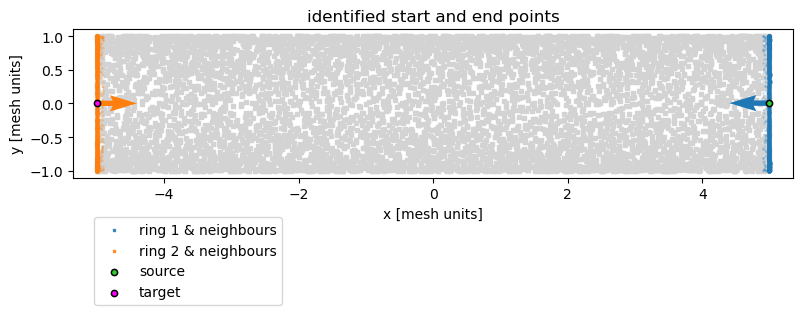

In [23]:
fig, ax2 = plt.subplots(1, 1, figsize = (8, 3))

## bottom graph: the mesh
ax2.scatter(*data.centroids[::50, [0,1]].T, **mesh_kwargs)

## mesh P1 and P2 neighbours
ax2.scatter(*data.centroids[P1_neighbours][::20, [0,1]].T, s = 1, alpha = 0.15, color = "C0", edgecolors=None)
ax2.scatter(*data.centroids[P2_neighbours][::20, [0,1]].T, s = 1, alpha = 0.15, color = "C1", edgecolors=None)

## inlet and outlet rings
ax2.scatter(*ring1[:, [0,1]].T, label = "ring 1 & neighbours", alpha = 0.8, color ="C0", zorder = -1, s = 2, marker = "s")
ax2.scatter(*ring2[:, [0,1]].T, label = "ring 2 & neighbours", color = "C1", alpha = 0.8, zorder = -1, s =2, marker="s")

## inlet and outlet
ax2.scatter(*P1[[0,1]].T, **start_kwargs)
ax2.scatter(*P2[[0,1]].T, **end_kwargs)
ax2.quiver(*P1[[0,1]].T, *sign_P1*nP1[[0, 1]].T, color="C0", zorder =0)
ax2.quiver(*P2[[0,1]].T, *sign_P2*nP2[[0, 1]].T, color= "C1", zorder = 0)

ax2.legend()
ax2.set_aspect("equal")
ax2.set_title("identified start and end points")
ax2.set_xlim(-5.35, 5.35)
ax2.set_xlabel("x [mesh units]")
ax2.set_ylabel("y [mesh units]")
ax2.legend(loc = "upper left", bbox_to_anchor= (0.02, -0.22))

plt.tight_layout()
#plt.savefig(f"{thedir}//{CONDUIT_NAME}_inlet_outlet.png")

